# Эксперименты с моделью детекции

Все попытки улучшить базовую модель `yolov8m-building-seg-1996bc04`: внешние датасеты (SpaceNet 2, footprints
Microsoft, AIRS, RID2), дообучение на своей разметке, аугментации, заморозка слоёв, масштаб входа. Ноутбук только
читает готовые результаты и хранится с выводами.

**Главная метрика — F1, взвешенный по площади** (D-023, `docs/metrics_and_formulas.md` §3а): здания весят своей
площадью, пропущенный многоквартирный дом важнее пропущенного сарая. Порог каждой модели выбирается по ней на `val`.
Обычный F1 (гейты G3–G5) приводится рядом.

**Два периода оценки.** До D-021 модели сравнивались на 11 тайлах (126 зданий), которые теперь `train`; после —
на `val`: 13 тайлов, 190 зданий, не участвовавших в обучении. Цифры периодов напрямую не сравниваются. Порог и
ранняя остановка подбирались на `val`, поэтому все числа `val` немного оптимистичны одинаково; независимая оценка —
однократно на `test`.

| Что | Откуда |
|---|---|
| F1 / F1 по площади по порогам (D-021) | `reports/experiments/weighted_f1_val.json` (`scripts/experiments/weighted_compare.py`) |
| результаты до D-021 | `reports/finetune_experiments_val.json`, `reports/experiments/imgsz_sweep_old_val.json` |
| кривые обучения | `reports/experiments/curves/*.csv` |
| детекции на `val` | `data/interim/experiments/det_val_*.geojson` (`geoqc cv predict --split val --weights … --conf 0.05`) |
| подготовка AIRS / RID2 | `reports/experiments/{airs,rid2}_prepared.json` |

In [ ]:
import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EXP = REPO_ROOT / "reports/experiments"
DET = REPO_ROOT / "data/interim/experiments"
FIG = REPO_ROOT / "docs/figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

W = json.loads((EXP / "weighted_f1_val.json").read_text())
NAMES = {
    "base_512": ("базовая", 512, "—"),
    "base_768": ("базовая", 768, "—"),
    "full_default": ("дообучение на train", 512, "train"),
    "full_aerial": ("дообучение на train + аэро-аугм.", 512, "train"),
    "head_aerial": ("только верхние слои + аэро-аугм.", 512, "train"),
    "head_aerial_768": ("только верхние слои + аэро-аугм.", 768, "train"),
    "full_aerial_768": ("дообучение на train + аэро-аугм.", 768, "train"),
    "airs_768": ("train + AIRS  ← рабочая (D-024)", 768, "train ×10 + AIRS 1318"),
    "airs_rid2_masked_768": ("+ RID2, крупные закрашены", 768, "+ AIRS 400 + RID2 400"),
    "airs_rid2_full_768": ("+ RID2, полная разметка", 768, "+ AIRS 400 + RID2 400"),
}
CHOSEN = "airs_768"

## 1. Сводная таблица (val, после D-021)

Для каждой модели — порог с лучшим F1 по площади. «Δ» — разница с базовой моделью на входе 768 (лучший вариант без
обучения).

In [ ]:
rows = []
for key, (name, imgsz, data) in NAMES.items():
    b = W[key]["best_by_f1_area"]
    rows.append({"модель": name, "вход": imgsz, "данные": data, "порог": b["conf"],
                 "F1 по площади": b["f1_area"], "F1": b["f1"], "P": b["precision"], "R": b["recall"],
                 "P по площади": b["precision_area"], "R по площади": b["recall_area"],
                 "IoU": b["mean_iou_matched"], "TP": b["tp"], "FP": b["fp"], "FN": b["fn"], "key": key})
res = pd.DataFrame(rows)
base = res.set_index("key").loc["base_768", "F1 по площади"]
res["Δ F1 по площади"] = res["F1 по площади"] - base
display(res.drop(columns="key").round(3).style.hide(axis="index")
        .background_gradient(subset=["Δ F1 по площади"], cmap="RdYlGn", vmin=-0.12, vmax=0.12)
        .apply(lambda r: ["font-weight: bold" if r["модель"].endswith("(D-024)") else "" for _ in r], axis=1))

модель,вход,данные,порог,F1 по площади,F1,P,R,P по площади,R по площади,IoU,TP,FP,FN,Δ F1 по площади
базовая,512,—,0.350000,0.835000,0.682000,0.904000,0.547000,0.900000,0.778000,0.820000,104,11,86,-0.035000
базовая,768,—,0.300000,0.869000,0.789000,0.862000,0.726000,0.925000,0.820000,0.823000,138,22,52,0.000000
дообучение на train,512,train,0.350000,0.835000,0.682000,0.904000,0.547000,0.901000,0.778000,0.817000,104,11,86,-0.034000
дообучение на train + аэро-аугм.,512,train,0.350000,0.836000,0.684000,0.912000,0.547000,0.903000,0.778000,0.818000,104,10,86,-0.033000
только верхние слои + аэро-аугм.,512,train,0.350000,0.835000,0.682000,0.904000,0.547000,0.901000,0.778000,0.820000,104,11,86,-0.034000
только верхние слои + аэро-аугм.,768,train,0.300000,0.869000,0.786000,0.857000,0.726000,0.925000,0.820000,0.822000,138,23,52,-0.000000
дообучение на train + аэро-аугм.,768,train,0.300000,0.873000,0.787000,0.867000,0.721000,0.935000,0.818000,0.823000,137,21,53,0.003000
train + AIRS ← рабочая (D-024),768,train ×10 + AIRS 1318,0.500000,0.978000,0.847000,0.881000,0.816000,0.982000,0.974000,0.835000,155,21,35,0.109000
"+ RID2, крупные закрашены",768,+ AIRS 400 + RID2 400,0.400000,0.978000,0.859000,0.839000,0.879000,0.973000,0.984000,0.835000,167,32,23,0.109000
"+ RID2, полная разметка",768,+ AIRS 400 + RID2 400,0.450000,0.973000,0.873000,0.858000,0.889000,0.960000,0.987000,0.832000,169,28,21,0.104000


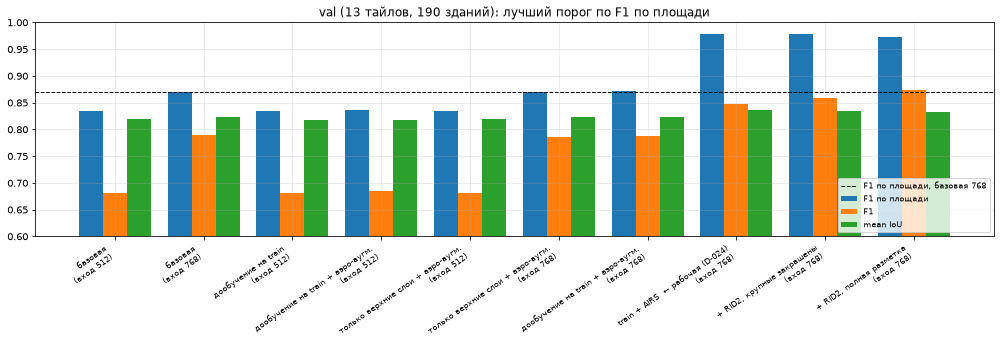

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(res))
for i, (col, label) in enumerate((("F1 по площади", "F1 по площади"), ("F1", "F1"), ("IoU", "mean IoU"))):
    ax.bar(x + (i - 1) * 0.27, res[col], width=0.27, label=label)
ax.axhline(base, color="black", ls="--", lw=1, label="F1 по площади, базовая 768")
ax.set_xticks(x, [f"{n}\n(вход {z})" for n, z in zip(res["модель"], res["вход"], strict=True)],
              rotation=35, ha="right", fontsize=8)
ax.set(ylim=(0.6, 1.0), title="val (13 тайлов, 190 зданий): лучший порог по F1 по площади")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "experiments_f1.png")
plt.show()

## 2. До D-021: внешние данные и масштаб входа

Оценка на 11 тайлах, которые теперь `train`; только обычный F1 (тогда метрика по площади ещё не считалась).

In [ ]:
old = json.loads((REPO_ROOT / "reports/finetune_experiments_val.json").read_text())
old_names = {"yolov8m-building-seg": "базовая", "yolov8m-building-seg-ft-spacenet": "дообучение: SpaceNet 2",
             "yolov8m-building-seg-ft-microsoft": "дообучение: footprints Microsoft"}
orows = [{"эксперимент": old_names[m["name"]], "вход": 512, "порог": m["best"]["conf"], "F1": m["best"]["f1"],
          "P": m["best"]["precision"], "R": m["best"]["recall"], "IoU": m["best"]["mean_iou_matched"]}
         for m in old["models"]]
imgsz = json.loads((EXP / "imgsz_sweep_old_val.json").read_text())["imgsz"]
for z, v in sorted(imgsz.items(), key=lambda kv: int(kv[0])):
    if z != "512":
        b = v["best"]
        orows.append({"эксперимент": "базовая, другой масштаб входа", "вход": int(z), "порог": b["conf"],
                      "F1": b["f1"], "P": b["precision"], "R": b["recall"], "IoU": b["mean_iou_matched"]})
display(pd.DataFrame(orows).round(3).style.hide(axis="index"))

эксперимент,вход,порог,F1,P,R,IoU
базовая,512,0.200000,0.774000,0.787000,0.762000,0.800000
дообучение: SpaceNet 2,512,0.100000,0.731000,0.709000,0.754000,0.783000
дообучение: footprints Microsoft,512,0.250000,0.722000,0.693000,0.754000,0.769000
"базовая, другой масштаб входа",640,0.150000,0.780000,0.696000,0.889000,0.801000
"базовая, другой масштаб входа",768,0.200000,0.790000,0.738000,0.849000,0.821000
"базовая, другой масштаб входа",1024,0.350000,0.778000,0.778000,0.778000,0.842000


## 3. Зависимость от порога

У моделей с AIRS плато F1 по площади — 0,40–0,65 (с RID2 — 0,40–0,55); ниже 0,40 падает точность по площади
(у train + AIRS до 0,5 при пороге 0,1): низкоуверенные детекции — крупные ложные контуры. У базовой плато 0,30–0,45.

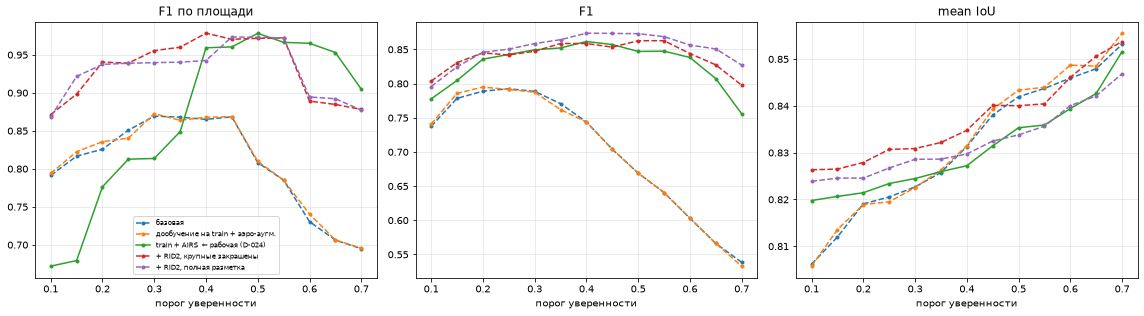

In [ ]:
show = ["base_768", "full_aerial_768", "airs_768", "airs_rid2_masked_768", "airs_rid2_full_768"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for key in show:
    t = pd.DataFrame(W[key]["thresholds"])
    style = "-" if key == CHOSEN else "--"
    for axi, col in zip(ax, ("f1_area", "f1", "mean_iou_matched"), strict=True):
        axi.plot(t.conf, t[col], style, marker="o", ms=3, label=NAMES[key][0])
for axi, title in zip(ax, ("F1 по площади", "F1", "mean IoU"), strict=True):
    axi.set(title=title, xlabel="порог уверенности")
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "experiments_thresholds.png")
plt.show()

## 4. Кривые обучения

mAP50 масок на holdout (для прогонов D-021, AIRS и RID2 — наш `val`; для SpaceNet и Microsoft — их собственный).
Лучшая эпоха — по сводному показателю Ultralytics 0,1·mAP50 + 0,9·mAP50-95 (по нему работает ранняя остановка).

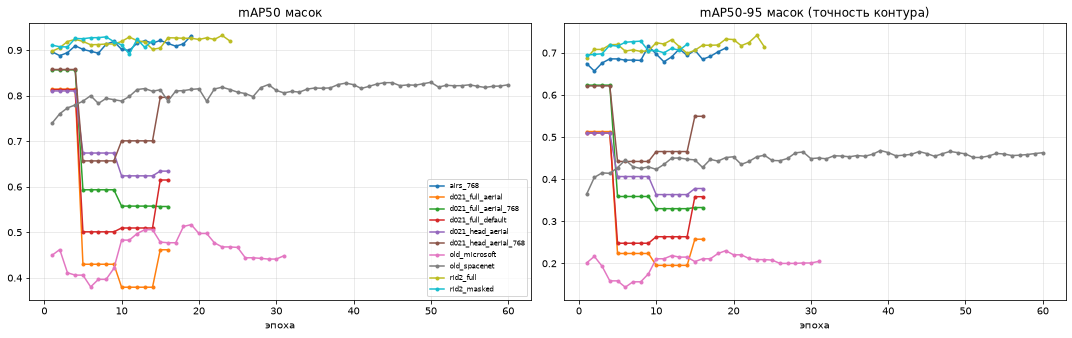

прогон,эпох,лучшая эпоха,mAP50(M),mAP50-95(M),мин/эпоха
airs_768,19,9,0.919000,0.716000,5.300000
d021_full_aerial,16,1,0.814000,0.513000,0.100000
d021_full_aerial_768,16,1,0.857000,0.623000,0.100000
d021_full_default,16,1,0.813000,0.509000,0.100000
d021_head_aerial,16,1,0.810000,0.509000,0.100000
d021_head_aerial_768,16,1,0.857000,0.621000,0.100000
old_microsoft,31,19,0.517000,0.230000,0.100000
old_spacenet,60,39,0.827000,0.468000,0.600000
rid2_full,24,23,0.932000,0.741000,4.400000
rid2_masked,14,8,0.929000,0.728000,3.800000


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
summary = []
for path in sorted((EXP / "curves").glob("*.csv")):
    c = pd.read_csv(path)
    c.columns = c.columns.str.strip()
    fit = 0.1 * c["metrics/mAP50(M)"] + 0.9 * c["metrics/mAP50-95(M)"]
    ax[0].plot(c.epoch, c["metrics/mAP50(M)"], marker=".", label=path.stem)
    ax[1].plot(c.epoch, c["metrics/mAP50-95(M)"], marker=".", label=path.stem)
    summary.append({"прогон": path.stem, "эпох": int(c.epoch.max()), "лучшая эпоха": int(c.epoch[fit.idxmax()]),
                    "mAP50(M)": round(float(c["metrics/mAP50(M)"][fit.idxmax()]), 3),
                    "mAP50-95(M)": round(float(c["metrics/mAP50-95(M)"][fit.idxmax()]), 3),
                    "мин/эпоха": round(float(c.time.diff().median() / 60), 1)})
ax[0].set(title="mAP50 масок", xlabel="эпоха")
ax[1].set(title="mAP50-95 масок (точность контура)", xlabel="эпоха")
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "experiments_curves.png")
plt.show()
display(pd.DataFrame(summary).style.hide(axis="index"))

## 5. По размерам зданий

Полнота — доля зданий класса `val`, найденных с IoU ≥ 0,5 (сопоставление 1:1, жадное); точность — доля детекций
класса, попавших в здание. Порог каждой модели — из таблицы раздела 1.

,зданий в val,базовая,дообучение на train + аэро-аугм.,train + AIRS ← рабочая (D-024),"+ RID2, крупные закрашены","+ RID2, полная разметка"
cls,,,,,,
12–30,70,0.429000,0.429000,0.571000,0.714000,0.714000
30–100,46,0.783000,0.761000,0.891000,0.935000,0.978000
100–500,60,0.983000,0.983000,1.000000,1.000000,1.000000
>500,14,0.929000,0.929000,1.000000,1.000000,1.000000


,базовая,дообучение на train + аэро-аугм.,train + AIRS ← рабочая (D-024),"+ RID2, крупные закрашены","+ RID2, полная разметка"
cls,,,,,
12–30,0.758000,0.743000,0.681000,0.652000,0.639000
30–100,0.804000,0.814000,0.875000,0.852000,0.912000
100–500,0.925000,0.939000,1.000000,0.985000,1.000000
>500,1.000000,1.000000,1.000000,1.000000,0.933000


модель,класс,зданий,найдено,ложных детекций,IoU найденных
базовая,≥ 100 м²,74,72,5,0.861000
базовая,≥ 500 м²,14,13,0,0.869000
дообучение на train + аэро-аугм.,≥ 100 м²,74,72,4,0.861000
дообучение на train + аэро-аугм.,≥ 500 м²,14,13,0,0.870000
train + AIRS ← рабочая (D-024),≥ 100 м²,74,74,0,0.882000
train + AIRS ← рабочая (D-024),≥ 500 м²,14,14,0,0.904000
"+ RID2, крупные закрашены",≥ 100 м²,74,74,1,0.889000
"+ RID2, крупные закрашены",≥ 500 м²,14,14,0,0.894000
"+ RID2, полная разметка",≥ 100 м²,74,74,1,0.887000
"+ RID2, полная разметка",≥ 500 м²,14,14,1,0.907000


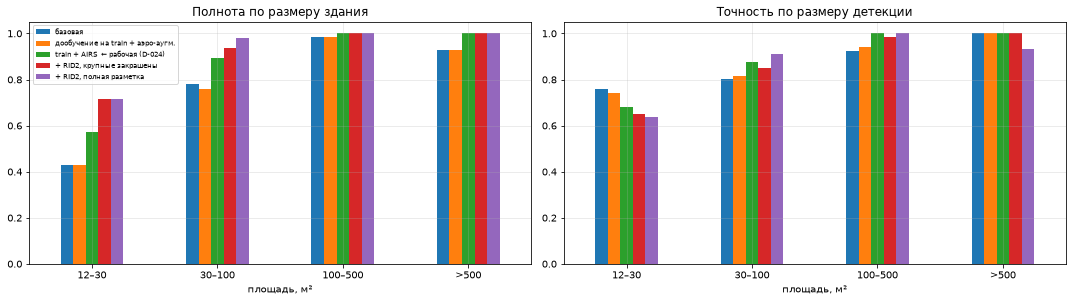

In [ ]:
split = pd.read_csv(REPO_ROOT / "data/labels/tiles_split.csv", dtype={"tile_id": str})
tiles = gpd.read_file(REPO_ROOT / "data/tiles/tiles.gpkg").to_crs(32636)
val_area = tiles[tiles.tile_id.isin(split.loc[split.split == "val", "tile_id"])].union_all()
gt = gpd.read_file(REPO_ROOT / "data/labels/val/buildings.geojson").to_crs(32636).reset_index(drop=True)
BINS, CLS = [12, 30, 100, 500, 1e9], ["12–30", "30–100", "100–500", ">500"]
gt["cls"] = pd.cut(gt.area, BINS, labels=CLS)


def evaluate(key: str) -> tuple[gpd.GeoDataFrame, dict]:
    conf = W[key]["best_by_f1_area"]["conf"]
    det = gpd.read_file(REPO_ROOT / W[key]["detections"]).to_crs(32636)
    det = det[det.score >= conf].copy()
    det["geometry"] = det.geometry.intersection(val_area)
    det = det[det.area >= 12].reset_index(drop=True)
    pairs = []
    for i, d in enumerate(det.geometry):
        for j in gt.sindex.query(d, predicate="intersects"):
            g = gt.geometry.iloc[j]
            iou = d.intersection(g).area / d.union(g).area
            if iou >= 0.5:
                pairs.append((iou, i, j))
    matched = {}
    used = set()
    for iou, i, j in sorted(pairs, reverse=True):
        if i not in used and j not in matched:
            used.add(i)
            matched[j] = iou
    det["hit"] = det.index.isin(used)
    det["cls"] = pd.cut(det.area, BINS, labels=CLS)
    return det, matched


compare = ["base_768", "full_aerial_768", "airs_768", "airs_rid2_masked_768", "airs_rid2_full_768"]
rec, prec, large = {}, {}, []
for key in compare:
    det, matched = evaluate(key)
    name = NAMES[key][0]
    hit_g = pd.Series(gt.index.isin(matched.keys()), index=gt.index)
    rec[name] = hit_g.groupby(gt.cls, observed=False).mean()
    prec[name] = det.hit.groupby(det.cls, observed=False).mean()
    for lo in (100, 500):
        g_idx = gt.index[gt.area >= lo]
        found = [j for j in g_idx if j in matched]
        large.append({"модель": name, "класс": f"≥ {lo} м²", "зданий": len(g_idx), "найдено": len(found),
                      "ложных детекций": int((~det.hit[det.area >= lo]).sum()),
                      "IoU найденных": round(float(np.mean([matched[j] for j in found])), 3)})
rec_df = pd.DataFrame(rec).reindex(CLS)
rec_df.insert(0, "зданий в val", gt.cls.value_counts().reindex(CLS).values)
display(rec_df.round(3).style.set_caption("Полнота по классам площади, м²"))
display(pd.DataFrame(prec).reindex(CLS).round(3).style.set_caption("Точность по классам площади детекций, м²"))
display(pd.DataFrame(large).style.hide(axis="index").set_caption("Крупные здания"))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
rec_df.drop(columns="зданий в val").plot.bar(ax=ax[0], rot=0, title="Полнота по размеру здания")
pd.DataFrame(prec).reindex(CLS).plot.bar(ax=ax[1], rot=0, title="Точность по размеру детекции", legend=False)
for axi in ax:
    axi.set(ylim=(0, 1.05), xlabel="площадь, м²")
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "experiments_size_classes.png")
plt.show()

## 6. Внешняя проверка: тестовая часть AIRS

95 снимков Крайстчерча, которые модели не видели (в обучении была только часть `train`): 1476 чипов 512 px при
0,3 м, 692 из них без зданий, 16 985 зданий. Это не наша территория, а новые тайлы знакомого по обучению города;
эталон — связные компоненты маски крыш (`scripts/experiments/airs_test_eval.py`).

модель,порог,F1 по площади,F1,P,R,IoU,R 12–30 м²,R 30–100 м²,R 100–500 м²,R >500 м²,TP,FP,FN
базовая,0.300000,0.723000,0.715000,0.850000,0.617000,0.813000,0.149000,0.493000,0.846000,0.511000,10487,1849,6498
train + AIRS ← рабочая (D-024),0.500000,0.924000,0.906000,0.956000,0.862000,0.865000,0.504000,0.875000,0.965000,0.878000,14633,669,2352


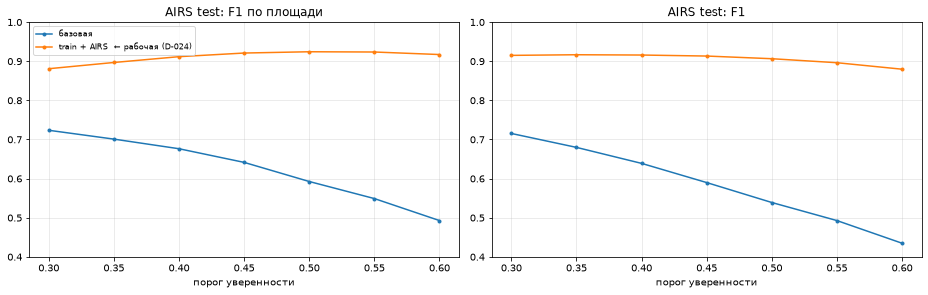

In [ ]:
A = json.loads((EXP / "airs_test.json").read_text())
arows = []
for key, m in A["models"].items():
    a = m["at_threshold"]
    arows.append({"модель": NAMES[key][0], "порог": m["threshold"], "F1 по площади": a["f1_area"], "F1": a["f1"],
                  "P": a["precision"], "R": a["recall"], "IoU": a["mean_iou_matched"],
                  **{f"R {k} м²": v["recall"] for k, v in a["recall_by_size"].items()},
                  "TP": a["tp"], "FP": a["fp"], "FN": a["fn"]})
display(pd.DataFrame(arows).round(3).style.hide(axis="index"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for key, m in A["models"].items():
    t = pd.DataFrame(m["thresholds"])
    ax[0].plot(t.conf, t.f1_area, marker="o", ms=3, label=NAMES[key][0])
    ax[1].plot(t.conf, t.f1, marker="o", ms=3, label=NAMES[key][0])
for axi, title in zip(ax, ("AIRS test: F1 по площади", "AIRS test: F1"), strict=True):
    axi.set(title=title, xlabel="порог уверенности", ylim=(0.4, 1.0))
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "experiments_airs_test.png")
plt.show()

## 7. Выводы

1. **Внешние данные «как есть» не помогают**, если не похожи на наш снимок: SpaceNet 2 (спутник, другие города) и
   footprints Microsoft (неточные контуры) ухудшили модель (D-019, D-020).
2. **Масштаб входа 768 вместо 512** — первый устойчивый выигрыш без обучения: F1 по площади 0,835 → 0,869,
   обычный F1 0,682 → 0,789; подтвердился на двух наборах тайлов.
3. **Дообучение только на своей разметке** (126 зданий; полное, только верхние слои, с аэро-аугментациями) по F1 по
   площади от базовой не отличается (0,835–0,873): ранняя остановка выбирает первые эпохи, дальше — подгонка под train.
4. **AIRS дал главный прирост**: F1 по площади 0,869 → **0,978**, модель находит 97–98 % площади застройки и все
   74 здания `val` от 100 м² без ложных срабатываний среди них; обычный F1 0,789 → 0,847, IoU 0,823 → 0,835. Аэрофото
   7,5 см с ручной разметкой крыш оказалось близким к нашему снимку (`notebooks/airs_eda.ipynb`).
5. **RID2** (Нидерланды) добавлялся адресно — 400 окон, где модель хуже всего находила мелкие постройки, без
   коллективных садов; вариант с закрашенными крупными зданиями учил только мелочь. Итог: F1 по площади на уровне AIRS
   (0,978 и 0,973), обычный F1 выше (0,859 и 0,873): полнота построек 12–30 м² 0,57 → 0,71, 30–100 м² 0,89 →
   0,94–0,98. Цена — точность на мелочи (0,68 → 0,64–0,65) и по одному ложному зданию от 100 м².
6. **Выбор (D-024)**: при равной главной метрике приоритет — крупные здания, поэтому рабочая модель — **train + AIRS,
   вход 768, порог 0,50**. Слабое место всех моделей — постройки 12–30 м² (полнота 0,43–0,71); для задачи контроля
   карты это наименее важный класс, а веса с RID2 сохранены, если приоритет сменится.
7. **Независимые цифры.** Наш `test` (10 новых тайлов, 153 здания, оценён один раз): F1 0,812, F1 по площади 0,926,
   mean IoU 0,807. Тестовая часть AIRS (раздел 6, 16 985 зданий): F1 0,906 и F1 по площади 0,924 против 0,715 и 0,723
   у базовой; порог 0,50, выбранный на нашем `val`, и там лучший по F1 по площади. Мелочь 12–30 м² остаётся слабым
   местом (полнота 0,50).
8. **Ограничения**: на `val` всего 190 зданий — разница 0,005 по F1 по площади и 0,01–0,02 по обычному F1 лежит в
   пределах шума; порог и ранняя остановка подбирались на `val`. AIRS test — новые тайлы знакомого по обучению города,
   а не наша территория.